In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sys

NOTEBOOK_DIR = Path.cwd().resolve()
if NOTEBOOK_DIR.name != "notebooks" and (NOTEBOOK_DIR / "notebooks").exists():
    NOTEBOOK_DIR = NOTEBOOK_DIR / "notebooks"
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))
ROOT = NOTEBOOK_DIR.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import ipywidgets as widgets
from IPython.display import display, clear_output
import cv2

from utils.suite2p_utils import get_neuron_outline
from utils.movie_utils import read_astro_movie
from db_notebook_utils import (
    available_experiments,
    load_confirmed_data,
    load_single_experiment_context,
    significant_cluster_counts,
    load_cluster_mask
)

# STA Cluster Responses From Confirmed Database

This notebook reads confirmed STA result and cluster rows from SQLite. Set `EXPERIMENT = None` for pooled analyses across all confirmed rows, or select one experiment for FOV visualizations.

In [2]:
# EXPERIMENT controls aggregate analyses.
# Set to None to analyze all confirmed database rows, or set to one canonical_id / experiment_id.
EXPERIMENT = None

# SINGLE_EXPERIMENT controls FOV/movie/example sections that cannot mix experiments.
# "auto" selects the first available experiment with confirmed cells, without hard-coding an ID.
# Set to a canonical_id / experiment_id to choose a specific experiment, or None to skip those sections.
SINGLE_EXPERIMENT = "Hyp6__R__25-05-2026_awake__FOV2__z-30__x2"

experiments_df = available_experiments()
display(experiments_df)

data = load_confirmed_data(EXPERIMENT)
print(f"Loaded {len(data.cells)} confirmed cells, {len(data.peaks)} peak rows, {len(data.sta_results)} STA result rows, {len(data.clusters)} clusters.")
if data.cells.empty:
    raise ValueError("No confirmed cells are available for the selected database scope.")

save_dir = Path(r"Z:\\Adam-Lab-Shared\\Data\\Miki_Meerson\\Stage A")


,experiment_id,canonical_id,source_path,recording_date,n_confirmed_cells
0,1,Hyp3__L__02-02-2026_awake__FOV1__z-18__x2,Z:\Adam-Lab-Shared\Data\Miki_Meerson\Imaging\H...,02-02-2026,26
1,2,Hyp6__R__25-05-2026_awake__FOV2__z-30__x2,Z:\Adam-Lab-Shared\Data\Miki_Meerson\Imaging\H...,25-05-2026,16
2,4,Hyp6__R__27-04-2026_awake__FOV1__z-110__x2,Z:\Adam-Lab-Shared\Data\Miki_Meerson\Imaging\H...,27-04-2026,0
3,3,Hyp3__L__30-12-2025_awake__FOV1__z-25__x4,Z:\Adam-Lab-Shared\Data\Miki_Meerson\Imaging\H...,30-12-2025,2


Loaded 44 confirmed cells, 44 peak rows, 199 STA result rows, 7385 clusters.


In [3]:
clusters = data.clusters.copy()
sta_results = data.sta_results.copy()
sig_clusters = clusters[clusters["is_significant"]].copy()

summary = (
    sta_results.groupby(["canonical_id", "result_type"])
    .agg(n_cells=("cell_id", "nunique"), n_results=("id", "count"), significant_clusters=("n_significant_clusters", "sum"))
    .reset_index()
)
display(summary)

,canonical_id,result_type,n_cells,n_results,significant_clusters
0,Hyp3__L__02-02-2026_awake__FOV1__z-18__x2,all,26,26,69
1,Hyp3__L__02-02-2026_awake__FOV1__z-18__x2,anatomy,26,26,21
2,Hyp3__L__02-02-2026_awake__FOV1__z-18__x2,behavioral_active,23,23,51
3,Hyp3__L__02-02-2026_awake__FOV1__z-18__x2,behavioral_inactive,2,2,1
4,Hyp3__L__02-02-2026_awake__FOV1__z-18__x2,complex,20,20,17
5,Hyp3__L__02-02-2026_awake__FOV1__z-18__x2,simple,19,19,44
6,Hyp3__L__30-12-2025_awake__FOV1__z-25__x4,all,2,2,1
7,Hyp3__L__30-12-2025_awake__FOV1__z-25__x4,anatomy,2,2,1
8,Hyp3__L__30-12-2025_awake__FOV1__z-25__x4,behavioral_active,2,2,1
9,Hyp3__L__30-12-2025_awake__FOV1__z-25__x4,simple,1,1,3


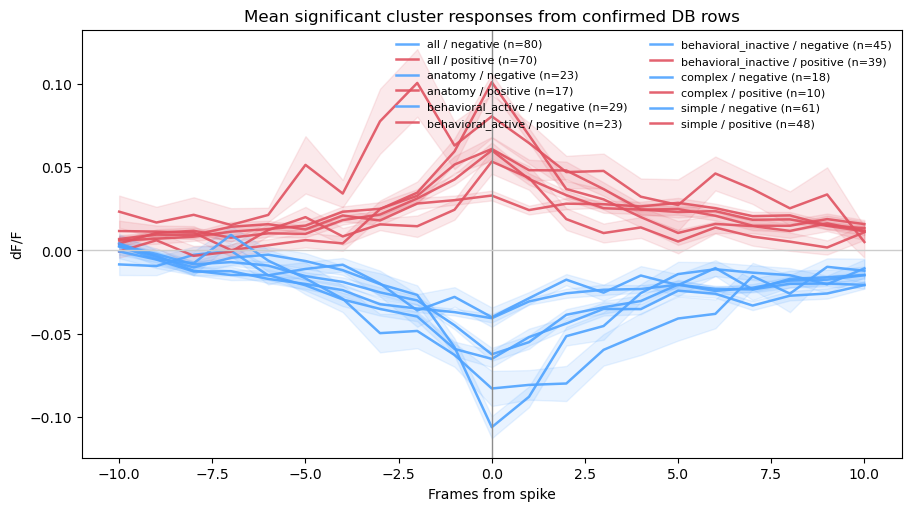

In [4]:
def mean_trace_table(cluster_df):
    rows = []
    for (result_type, sign), g in cluster_df.groupby(["result_type", "sign"], sort=True):
        traces = [np.asarray(t, dtype=float) for t in g["mean_trace"] if np.asarray(t).size]
        if not traces:
            continue
        min_len = min(t.size for t in traces)
        arr = np.vstack([t[:min_len] for t in traces])
        t_rel = np.asarray(g.iloc[0]["t_rel"], dtype=int)[:min_len]
        rows.append({"result_type": result_type, "sign": sign, "n_clusters": arr.shape[0], "t_rel": t_rel, "mean": arr.mean(axis=0), "sem": arr.std(axis=0) / np.sqrt(arr.shape[0])})
    return rows

trace_rows = mean_trace_table(sig_clusters)
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
colors = {"positive": "#E05260", "negative": "#4FA3FF"}
for row in trace_rows:
    label = f"{row['result_type']} / {row['sign']} (n={row['n_clusters']})"
    x = row["t_rel"]
    y = row["mean"]
    sem = row["sem"]
    color = colors.get(str(row["sign"]).lower(), "0.35")
    ax.plot(x, y, label=label, color=color, linewidth=1.8, alpha=0.9)
    ax.fill_between(x, y - sem, y + sem, color=color, alpha=0.12)
ax.axvline(0, color="0.55", linewidth=1)
ax.axhline(0, color="0.8", linewidth=1)
ax.set_title("Mean significant cluster responses from confirmed DB rows")
ax.set_xlabel("Frames from spike")
ax.set_ylabel("dF/F")
ax.legend(frameon=False, fontsize=8, ncol=2)
plt.show()


In [ ]:
# Grand averages by result type, with depolarizing and hyperpolarizing shown together per group.
# Astrocyte polarity colors follow the original notebook: depolarizing = red, hyperpolarizing = blue, neuron STA = orange.
neuron_color = "orange"
hyper_color = "blue"
de_color = "red"
astro_color = "purple"
polarity_label = {"positive": "depolarizing", "negative": "hyperpolarizing"}
polarity_color = {"positive": de_color, "negative": hyper_color}
linestyles = {
    "all": "-",
    "anatomy": "--",
    "behavioral_active": "-.",
    "behavioral_inactive": ":",
}
peak_column_by_result_type = {
    "simple": "simple_peaks",
    "complex": "complex_peaks",
}

_context_cache = {}
def context_for_experiment(experiment_id):
    experiment_id = int(experiment_id)
    if experiment_id not in _context_cache:
        exp_name = data.cells.loc[data.cells["experiment_id"].eq(experiment_id), "canonical_id"].iloc[0]
        _context_cache[experiment_id] = load_single_experiment_context(load_confirmed_data(exp_name))
    return _context_cache[experiment_id]

peak_lookup = {
    (int(r.experiment_id), int(r.cell_id)): r
    for r in data.peaks.itertuples()
}

def robust_dff(trace, baseline_percentile=8):
    y = np.asarray(trace, dtype=float).ravel()
    if y.size == 0:
        return y
    f0 = float(np.nanpercentile(y, baseline_percentile))
    if not np.isfinite(f0):
        return y
    return (y - f0) / (abs(f0) + 1e-6)

def compute_raw_sta_from_peaks(neuron_trace, peaks, pre_frames, post_frames):
    t = np.asarray(neuron_trace, dtype=float).ravel()
    sta_len = int(pre_frames + post_frames + 1)
    if t.size == 0:
        return np.full(sta_len, np.nan, dtype=float)
    pks = np.asarray(peaks, dtype=np.int32).ravel()
    if pks.size == 0:
        return np.full(sta_len, np.nan, dtype=float)
    trials = []
    for p in pks:
        a = int(p - pre_frames)
        b = int(p + post_frames + 1)
        if a < 0 or b > t.size:
            continue
        seg = np.asarray(t[a:b], dtype=float)
        if seg.size == sta_len:
            trials.append(seg)
    if not trials:
        return np.full(sta_len, np.nan, dtype=float)
    return np.nanmean(np.stack(trials, axis=0), axis=0)

def baseline_center_sta(sta_trace, baseline_frames=10):
    y = np.asarray(sta_trace, dtype=float).ravel()
    if y.size == 0:
        return y
    n_base = min(int(baseline_frames), y.size)
    baseline = float(np.nanmean(y[:max(1, n_base)]))
    if not np.isfinite(baseline):
        return y
    return y - baseline

def peak_array_for_result_type(experiment_id, cell_id, result_type):
    row = peak_lookup.get((int(experiment_id), int(cell_id)))
    if row is None:
        return np.asarray([], dtype=np.int32)
    column = peak_column_by_result_type.get(str(result_type), "all_peaks")
    return np.asarray(getattr(row, column), dtype=np.int32)

def neuron_sta_for_cells(cell_group, result_type, t_rel):
    pre_frames = int(abs(np.nanmin(t_rel)))
    post_frames = int(np.nanmax(t_rel))
    traces = []
    seen = set()
    for row in cell_group.itertuples():
        key = (int(row.experiment_id), int(row.cell_id))
        if key in seen:
            continue
        seen.add(key)
        peaks = peak_array_for_result_type(row.experiment_id, row.cell_id, result_type)
        if peaks.size == 0:
            continue
        ctx = context_for_experiment(row.experiment_id)
        F = np.asarray(ctx.suite2p_ctx["F"], dtype=np.float32)
        if int(row.cell_id) >= F.shape[0]:
            continue
        trace_dff = robust_dff(F[int(row.cell_id)])
        sta = compute_raw_sta_from_peaks(trace_dff, peaks, pre_frames, post_frames)
        sta = baseline_center_sta(sta, baseline_frames=min(10, pre_frames))
        if sta.size == len(t_rel) and np.isfinite(sta).any():
            traces.append(sta)
    if not traces:
        return None
    arr = np.vstack(traces)
    return {"mean": np.nanmean(arr, axis=0), "sem": np.nanstd(arr, axis=0) / np.sqrt(arr.shape[0]), "n_cells": arr.shape[0]}

def build_average_rows(cluster_df):
    rows = []
    for (result_type, sign), g in cluster_df.groupby(["result_type", "sign"], sort=True):
        traces = [np.asarray(t, dtype=float) for t in g["mean_trace"] if np.asarray(t).size]
        if not traces:
            continue
        min_len = min(t.size for t in traces)
        arr = np.vstack([t[:min_len] for t in traces])
        t_rel = np.asarray(g.iloc[0]["t_rel"], dtype=int)[:min_len]
        rows.append(
            {
                "key": f"{result_type}__{sign}",
                "result_type": str(result_type),
                "sign": str(sign),
                "label": f"{polarity_label.get(str(sign).lower(), sign)} (astro n={arr.shape[0]})",
                "t_rel": t_rel,
                "mean": arr.mean(axis=0),
                "sem": arr.std(axis=0) / np.sqrt(arr.shape[0]),
                "n_clusters": arr.shape[0],
            }
        )
    return rows

def center_zero_ylim(ax, pad=0.08):
    ymin, ymax = ax.get_ylim()
    finite = [abs(v) for v in (ymin, ymax) if np.isfinite(v)]
    radius = max(finite) if finite else 1.0
    if radius == 0:
        radius = 1.0
    radius *= 1 + float(pad)
    ax.set_ylim(-radius, radius)

def symmetric_ylim(values, pad=0.08, min_half_range=0.05, percentiles=None):
    y = np.asarray(values, dtype=float).ravel()
    y = y[np.isfinite(y)]
    if y.size == 0:
        return (-min_half_range, min_half_range)
    if percentiles is None:
        lo, hi = float(np.nanmin(y)), float(np.nanmax(y))
    else:
        lo, hi = np.nanpercentile(y, percentiles)
    radius = max(abs(float(lo)), abs(float(hi)), float(min_half_range))
    radius *= 1 + float(pad)
    return (-radius, radius)

def grand_average_widget(cluster_df, title="Grand average STA clusters with neuron STA overlay"):
    cluster_df = cluster_df.copy()
    grand_average_rows = build_average_rows(cluster_df[~cluster_df["result_type"].isin(["simple", "complex"])]).copy()
    if not grand_average_rows:
        raise ValueError("No significant non-simple/complex cluster traces are available for the selected DB scope.")

    result_groups = sorted({row["result_type"] for row in grand_average_rows})
    checkboxes = {
        result_type: widgets.Checkbox(value=True, description=result_type, indent=False)
        for result_type in result_groups
    }
    output = widgets.Output()

    def redraw(*_):
        with output:
            clear_output(wait=True)
            fig, ax = plt.subplots(figsize=(10.5, 5.8), constrained_layout=True)
            ax_astro = ax.twinx()
            any_visible = False
            for result_type in result_groups:
                if not checkboxes[result_type].value:
                    continue
                linestyle = linestyles.get(result_type, "-")
                rows_for_group = [r for r in grand_average_rows if r["result_type"] == result_type]
                if not rows_for_group:
                    continue
                t_rel = rows_for_group[0]["t_rel"]
                neuron_source = cluster_df[cluster_df["result_type"].eq(result_type)]
                neuron_sta = neuron_sta_for_cells(neuron_source, result_type, t_rel)
                if neuron_sta is not None:
                    ny = neuron_sta["mean"]
                    nsem = neuron_sta["sem"]
                    ax.plot(
                        t_rel,
                        ny,
                        color=neuron_color,
                        linestyle=linestyle,
                        linewidth=1.8,
                        alpha=0.9,
                        label=f"neuron STA / {result_type} (cells n={neuron_sta['n_cells']})",
                    )
                    ax.fill_between(t_rel, ny - nsem, ny + nsem, color=neuron_color, alpha=0.08)
                for row in rows_for_group:
                    any_visible = True
                    sign = row["sign"].lower()
                    astro_color = polarity_color.get(sign, "0.35")
                    x = row["t_rel"]
                    y = row["mean"]
                    sem = row["sem"]
                    ax_astro.plot(x, y, color=astro_color, linestyle=linestyle, linewidth=2.1, label=f"{result_type} / {row['label']}")
                    ax_astro.fill_between(x, y - sem, y + sem, color=astro_color, alpha=0.12)
            center_zero_ylim(ax)
            center_zero_ylim(ax_astro)
            ax.axvline(0, color="0.55", linewidth=1)
            ax.axhline(0, color="0.8", linewidth=1)
            ax.set_title(title)
            ax.set_xlabel("Frames from spike")
            ax.set_ylabel("Neuron dF/F", color=neuron_color)
            ax_astro.set_ylabel("Astrocyte dF/F")
            ax.tick_params(axis="y", colors=neuron_color)
            if any_visible:
                handles_left, labels_left = ax.get_legend_handles_labels()
                handles_right, labels_right = ax_astro.get_legend_handles_labels()
                dedup = dict(zip(labels_left + labels_right, handles_left + handles_right))
                ax.legend(dedup.values(), dedup.keys(), frameon=False, fontsize=7.5, ncol=2)
            else:
                ax.text(0.5, 0.5, "No groups selected", transform=ax.transAxes, ha="center", va="center", color="0.4")
            ax.spines[["top"]].set_visible(False)
            ax_astro.spines[["top"]].set_visible(False)

            fig.savefig(save_dir / "fig2/db_grand_avg.svg", format="svg", bbox_inches="tight")
            plt.show()

    for checkbox in checkboxes.values():
        checkbox.observe(redraw, names="value")

    controls = widgets.VBox([
        widgets.HTML("<b>Show / hide result groups</b>"),
        widgets.HBox(list(checkboxes.values())),
    ])
    widget = widgets.VBox([controls, output])
    display(widget)
    redraw()
    return widget

all_experiments_grand_average = grand_average_widget(
    sig_clusters,
    title="Grand average STA clusters with neuron STA overlay",
)


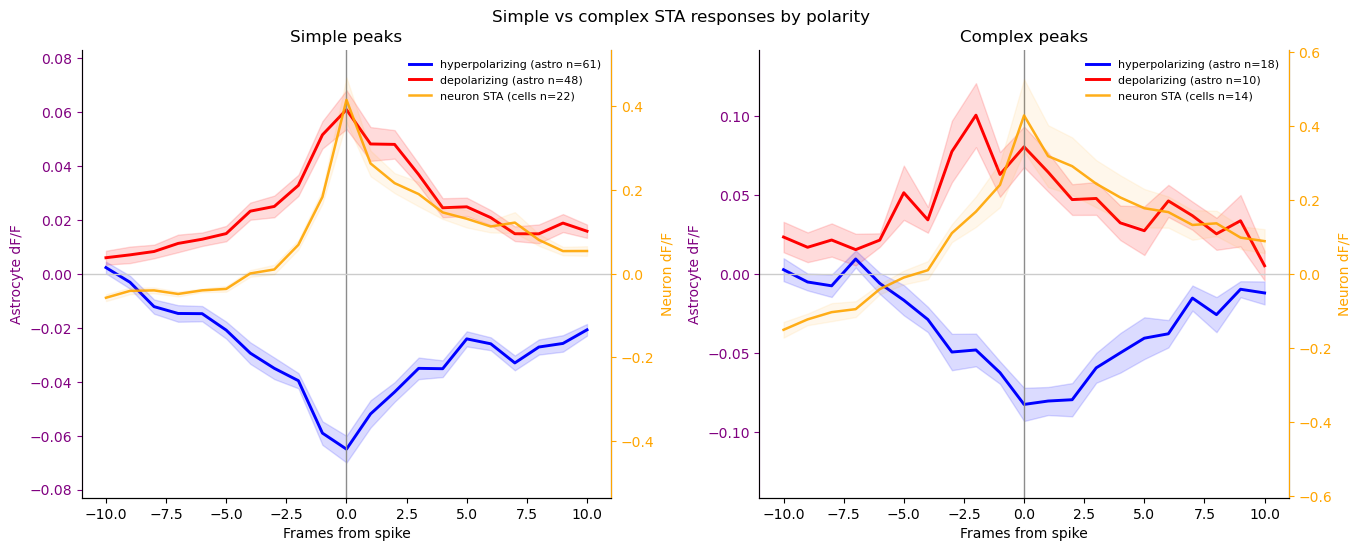

In [6]:
# Simple vs complex response comparison. Two static panels; each panel includes depolarizing, hyperpolarizing, and neuron STA overlays.
subset = sig_clusters[sig_clusters["result_type"].isin(["simple", "complex"])]
if subset.empty:
    print("No confirmed simple/complex STA clusters are available in the selected DB scope.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), constrained_layout=True)
    for ax, result_type in zip(axes, ["simple", "complex"]):
        ax_neuron = ax.twinx()
        g_type = subset[subset["result_type"].eq(result_type)]
        if g_type.empty:
            ax.text(0.5, 0.5, f"No {result_type} clusters", transform=ax.transAxes, ha="center", va="center", color="0.4")
            ax.set_axis_off()
            ax_neuron.set_axis_off()
            continue
        neuron_overlay_drawn = False
        for sign, g in g_type.groupby("sign", sort=True):
            traces = [np.asarray(t, dtype=float) for t in g["mean_trace"] if np.asarray(t).size]
            if not traces:
                continue
            min_len = min(t.size for t in traces)
            arr = np.vstack([t[:min_len] for t in traces])
            x = np.asarray(g.iloc[0]["t_rel"], dtype=int)[:min_len]
            y = arr.mean(axis=0)
            sem = arr.std(axis=0) / np.sqrt(arr.shape[0])
            sign_key = str(sign).lower()
            color = polarity_color.get(sign_key, "0.35")
            ax.plot(x, y, color=color, linewidth=2.1, label=f"{polarity_label.get(sign_key, sign)} (astro n={arr.shape[0]})")
            ax.fill_between(x, y - sem, y + sem, color=color, alpha=0.14)
            if not neuron_overlay_drawn:
                neuron_sta = neuron_sta_for_cells(g_type, result_type, x)
                if neuron_sta is not None:
                    ny = neuron_sta["mean"]
                    nsem = neuron_sta["sem"]
                    ax_neuron.plot(x, ny, color=neuron_color, linewidth=1.8, alpha=0.9, label=f"neuron STA (cells n={neuron_sta['n_cells']})")
                    ax_neuron.fill_between(x, ny - nsem, ny + nsem, color=neuron_color, alpha=0.08)
                neuron_overlay_drawn = True
        ax.axvline(0, color="0.55", linewidth=1)
        ax.axhline(0, color="0.8", linewidth=1)
        center_zero_ylim(ax)
        center_zero_ylim(ax_neuron)
        ax.set_title(f"{result_type.title()} peaks")
        ax.set_xlabel("Frames from spike")
        ax.set_ylabel("Astrocyte dF/F", color=astro_color)
        ax_neuron.set_ylabel("Neuron dF/F", color=neuron_color)
        ax.tick_params(axis="y", colors=astro_color)
        ax_neuron.tick_params(axis="y", colors=neuron_color)
        ax.spines["left"].set_color(astro_color)
        ax_neuron.spines["right"].set_color(neuron_color)
        ax.spines[["top"]].set_visible(False)
        ax_neuron.spines[["top"]].set_visible(False)
        handles_left, labels_left = ax.get_legend_handles_labels()
        handles_right, labels_right = ax_neuron.get_legend_handles_labels()
        ax.legend(handles_left + handles_right, labels_left + labels_right, frameon=False, fontsize=8)
    fig.suptitle("Simple vs complex STA responses by polarity", y=1.03)
    plt.show()


## Single-Experiment Setup

The following sections restore the original notebook-style FOV, trace, example-cell, and raw-cluster analyses. They use only confirmed database rows and automatically select available cells. Set `EXPERIMENT` in the setup cell to one available experiment to run them.


In [7]:
# Single-experiment data used by FOV, trace, and example-response sections.
# These sections intentionally skip when EXPERIMENT=None because FOV/movie visualizations cannot mix experiments.

neuron_color = "orange"
hyper_color = "blue"
de_color = "red"
astro_color = "purple"
polarity_label = {"positive": "depolarizing", "negative": "hyperpolarizing"}
polarity_color = {"positive": de_color, "negative": hyper_color}

single_experiment_ready = False
single_experiment_choice = SINGLE_EXPERIMENT
if single_experiment_choice == "auto":
    available_single = experiments_df[experiments_df["n_confirmed_cells"].astype(int) > 0].copy()
    single_experiment_choice = None if available_single.empty else available_single.iloc[0]["canonical_id"]
elif single_experiment_choice is None and EXPERIMENT is not None:
    single_experiment_choice = EXPERIMENT

if single_experiment_choice is None:
    print("Single-experiment sections skipped. Set SINGLE_EXPERIMENT to an available canonical_id/experiment_id to plot FOV, traces, examples, and raw movie analyses.")
else:
    try:
        single_data = load_confirmed_data(single_experiment_choice)
        ctx = load_single_experiment_context(single_data)
    except ValueError as exc:
        print(exc)
    else:
        single_experiment_ready = True
        exp_cells = single_data.cells[single_data.cells["experiment_id"].eq(ctx.experiment_id)].copy()
        exp_peaks = single_data.peaks[single_data.peaks["experiment_id"].eq(ctx.experiment_id)].copy()
        exp_clusters = single_data.clusters[single_data.clusters["experiment_id"].eq(ctx.experiment_id)].copy()
        exp_sta_results = single_data.sta_results[single_data.sta_results["experiment_id"].eq(ctx.experiment_id)].copy()
        exp_sig_clusters = exp_clusters[exp_clusters["is_significant"]].copy()
        sig_counts_single = significant_cluster_counts(exp_clusters)
        exp_peaks["n_sig_clusters"] = exp_peaks["cell_id"].map(lambda c: int(sig_counts_single.get((ctx.experiment_id, int(c)), 0)))
        example_cell_ids = exp_peaks.sort_values(["n_sig_clusters", "n_all_peaks", "cell_id"], ascending=[False, False, True])["cell_id"].to_numpy(dtype=int)
        print(f"Single-experiment sections loaded {ctx.canonical_id}: {len(exp_cells)} confirmed cells, {len(exp_sig_clusters)} significant clusters.")

def robust_dff(trace, baseline_percentile=8):
    y = np.asarray(trace, dtype=float).ravel()
    if y.size == 0:
        return y
    f0 = float(np.nanpercentile(y, baseline_percentile))
    if not np.isfinite(f0):
        return y
    return (y - f0) / (abs(f0) + 1e-6)

def compute_raw_sta_from_peaks(neuron_trace, peaks, pre_frames, post_frames):
    t = np.asarray(neuron_trace, dtype=float).ravel()
    sta_len = int(pre_frames + post_frames + 1)
    if t.size == 0:
        return np.full(sta_len, np.nan, dtype=float)
    pks = np.asarray(peaks, dtype=np.int32).ravel()
    if pks.size == 0:
        return np.full(sta_len, np.nan, dtype=float)
    trials = []
    for p in pks:
        a = int(p - pre_frames)
        b = int(p + post_frames + 1)
        if a < 0 or b > t.size:
            continue
        seg = np.asarray(t[a:b], dtype=float)
        if seg.size == sta_len:
            trials.append(seg)
    if not trials:
        return np.full(sta_len, np.nan, dtype=float)
    return np.nanmean(np.stack(trials, axis=0), axis=0)

def baseline_center_sta(sta_trace, baseline_frames=10):
    y = np.asarray(sta_trace, dtype=float).ravel()
    if y.size == 0:
        return y
    n_base = min(int(baseline_frames), y.size)
    baseline = float(np.nanmean(y[:max(1, n_base)]))
    if not np.isfinite(baseline):
        return y
    return y - baseline

def add_trace_scale_bar(ax, time_seconds=30, dff_fraction=0.5, color="black", loc="lower right"):
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    x_range = x1 - x0
    y_range = y1 - y0
    if "left" in loc:
        x_start = x0 + 0.08 * x_range
        text_ha = "left"
        text_x = x_start + 0.012 * x_range
    else:
        x_start = x1 - 0.08 * x_range - time_seconds
        text_ha = "right"
        text_x = x_start - 0.012 * x_range
    y_start = y0 + 0.10 * y_range
    ax.plot([x_start, x_start + time_seconds], [y_start, y_start], color=color, linewidth=1.2, solid_capstyle="butt", zorder=5)
    ax.plot([x_start, x_start], [y_start, y_start + dff_fraction], color=color, linewidth=1.2, solid_capstyle="butt", zorder=5)
    ax.text(x_start + time_seconds / 2, y_start - 0.025 * y_range, f"{time_seconds:g} s", ha="center", va="top", fontsize=8, color=color)
    ax.text(text_x, y_start + dff_fraction / 2, f"{100 * dff_fraction:g}% dF/F", ha=text_ha, va="center", rotation=90, fontsize=8, color=color)

def add_image_scale_bar(ax, image_shape, full_fov_um=406, bar_um=2, color="white"):
    height_px, width_px = int(image_shape[0]), int(image_shape[1])
    um_per_px = float(full_fov_um) / float(width_px)
    bar_px = float(bar_um) / um_per_px
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    x_min, x_max = sorted((x0, x1))
    y_min, y_max = sorted((y0, y1))
    pad_x = 0.10 * (x_max - x_min)
    pad_y = 0.10 * (y_max - y_min)
    x_start = x_max - pad_x - bar_px
    y_start = y_max - pad_y
    ax.plot([x_start, x_start + bar_px], [y_start, y_start], color=color, linewidth=2.0, solid_capstyle="butt", zorder=6)
    ax.text(x_start + bar_px / 2, y_start - 0.04 * (y_max - y_min), f"{bar_um:g} Âµm", ha="center", va="bottom", fontsize=7, color=color, zorder=6)

def _to_display_mask(mask2d, spatial_bin, display_shape):
    m = np.asarray(mask2d, dtype=np.float32)

    if int(spatial_bin) > 1:
        h = int(m.shape[0] * int(spatial_bin))
        w = int(m.shape[1] * int(spatial_bin))
        m = cv2.resize(m, (w, h), interpolation=cv2.INTER_LINEAR)

    if m.shape != tuple(display_shape):
        m = cv2.resize(m, (int(display_shape[1]), int(display_shape[0])), interpolation=cv2.INTER_LINEAR)

    m = cv2.GaussianBlur(m, (5, 5), 1.0)
    return m
def full_fov_mask_from_row(row, image_shape):
    mask = load_cluster_mask(row)
    if mask is None:
        return None
    # Anatomy masks are crop-local. Without crop bounds in the confirmed cluster row, do not stretch them to the whole FOV.
    if str(row.get("result_type", "")) == "anatomy":
        return None
    return _to_display_mask(mask, spatial_bin=1, display_shape=image_shape)


Single-experiment sections loaded Hyp6__R__25-05-2026_awake__FOV2__z-30__x2: 16 confirmed cells, 254 significant clusters.


## Single-Experiment Grand Average


In [8]:
if single_experiment_ready:
    single_experiment_grand_average = grand_average_widget(
        exp_sig_clusters,
        title=f"{ctx.canonical_id}: grand average STA clusters with neuron STA overlay",
    )
else:
    print("Single-experiment grand average skipped: set SINGLE_EXPERIMENT to one available experiment.")


## FOV Visualizations


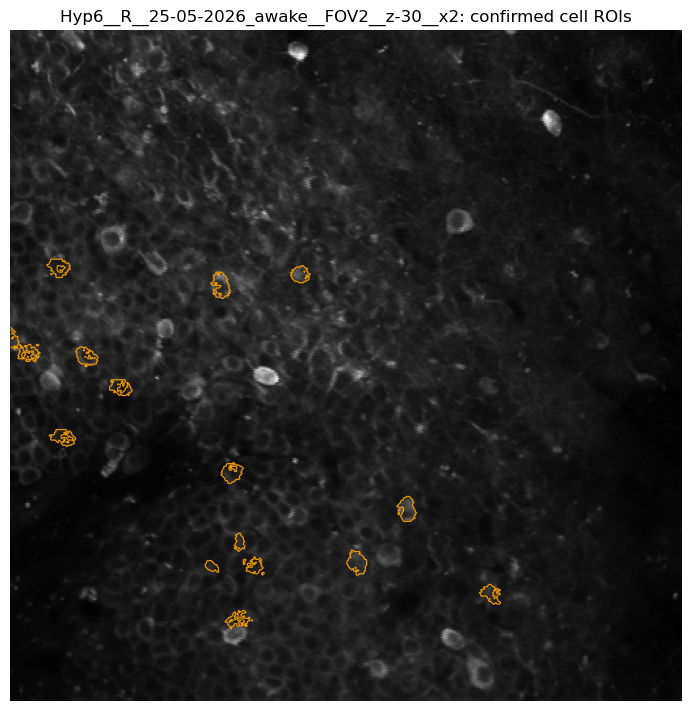

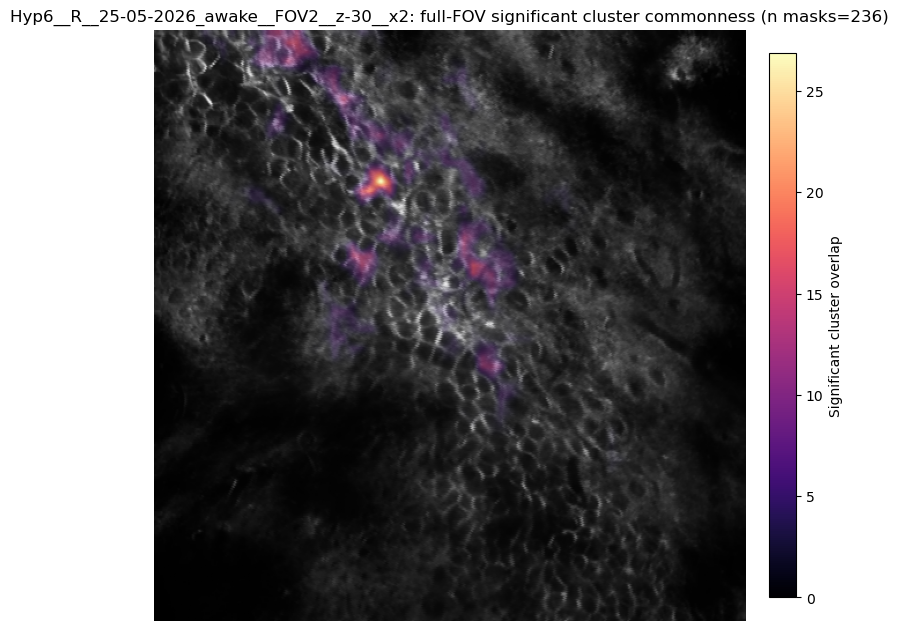

In [9]:
if single_experiment_ready:
    fig, ax = plt.subplots(figsize=(7, 7), constrained_layout=True)
    ax.imshow(ctx.neuron_mean_img, cmap="gray")
    sig_cell_ids = set(exp_sig_clusters["cell_id"].astype(int).unique())
    for cell_id in exp_cells["pipeline_neuron_id"].astype(int).sort_values():
        outline = get_neuron_outline(int(cell_id), ctx.paths.suite2p_path, ctx.image_shape, spatial_bin=1)
        color = neuron_color if int(cell_id) in sig_cell_ids else "0.55"
        ax.contour(outline.astype(float), levels=[0.5], colors=[color], linewidths=0.9, alpha=0.9)
    ax.set_title(f"{ctx.canonical_id}: confirmed cell ROIs")
    ax.set_axis_off()
    plt.show()

    commonness = np.zeros(ctx.image_shape, dtype=np.float32)
    used_masks = 0
    for _, row in exp_sig_clusters.iterrows():
        mask = full_fov_mask_from_row(row, ctx.image_shape)
        if mask is None:
            continue
        commonness += mask.astype(np.float32)
        used_masks += 1

    fig, ax = plt.subplots(figsize=(7, 7), constrained_layout=True)
    ax.imshow(ctx.astro_mean_img, cmap="gray")
    alpha = np.clip(commonness / max(1, commonness.max()), 0, 1) ** 0.8
    im = ax.imshow(commonness, cmap="magma", alpha=alpha)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Significant cluster overlap")
    ax.set_title(f"{ctx.canonical_id}: full-FOV significant cluster commonness (n masks={used_masks})")
    ax.set_axis_off()
    plt.show()
else:
    print('FOV visualizations skipped: set SINGLE_EXPERIMENT to one available experiment.')


## All Confirmed Neuron Traces


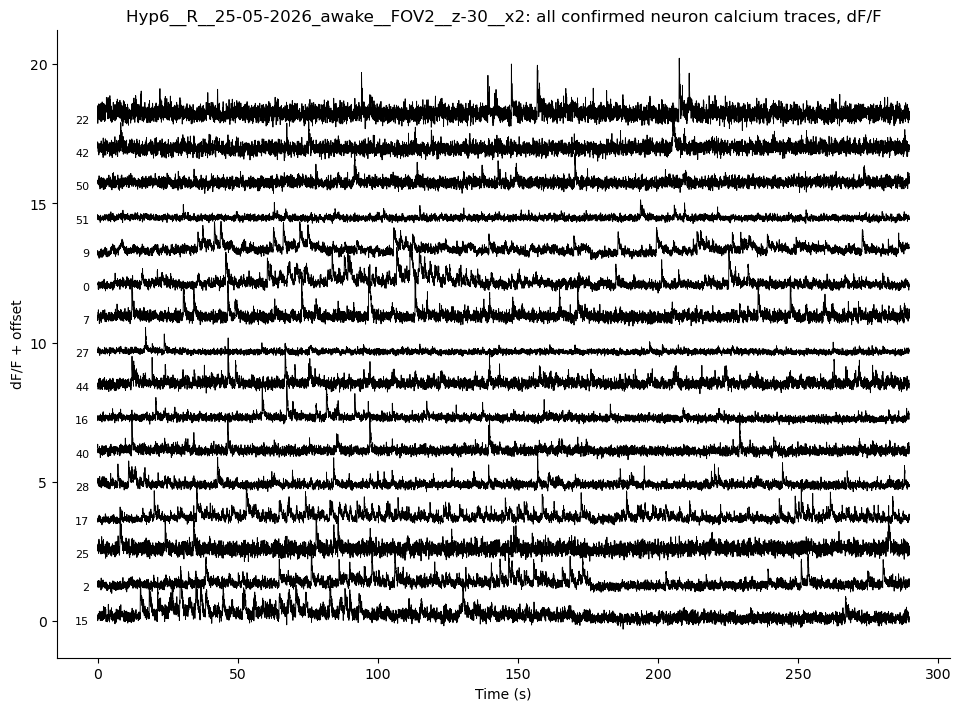

In [10]:
if single_experiment_ready:
    F = np.asarray(ctx.suite2p_ctx["F"], dtype=np.float32)
    ordered = exp_peaks.sort_values(["n_sig_clusters", "n_all_peaks", "cell_id"], ascending=[False, False, True])["cell_id"].to_numpy(dtype=int)
    fig, ax = plt.subplots(figsize=(9.5, max(7, 0.38 * len(ordered))), constrained_layout=True)
    offset = 0.0
    for cell_id in ordered:
        if cell_id >= F.shape[0]:
            continue
        y = robust_dff(F[cell_id])
        ax.plot(np.arange(y.size) / ctx.fps, y + offset, color="black", linewidth=0.65)
        ax.text(-0.01 * y.size / ctx.fps, offset, str(cell_id), ha="right", va="center", fontsize=8)
        offset += max(1.2, np.nanpercentile(y, 99) - np.nanpercentile(y, 1))
    ax.set_title(f"{ctx.canonical_id}: all confirmed neuron calcium traces, dF/F")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("dF/F + offset")
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()
else:
    print('All confirmed neuron traces skipped: set SINGLE_EXPERIMENT to one available experiment.')


## Automatically Selected Example Cells


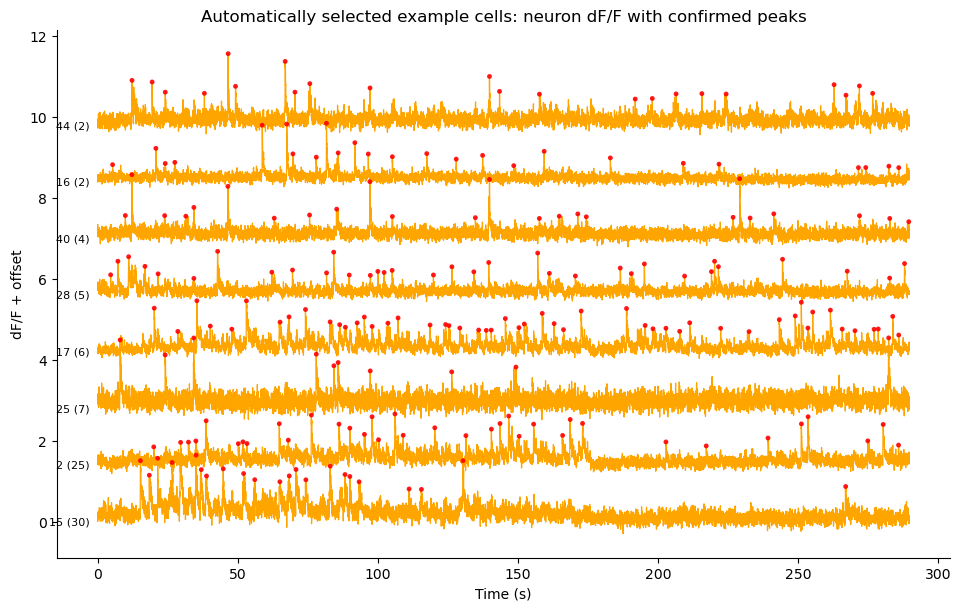

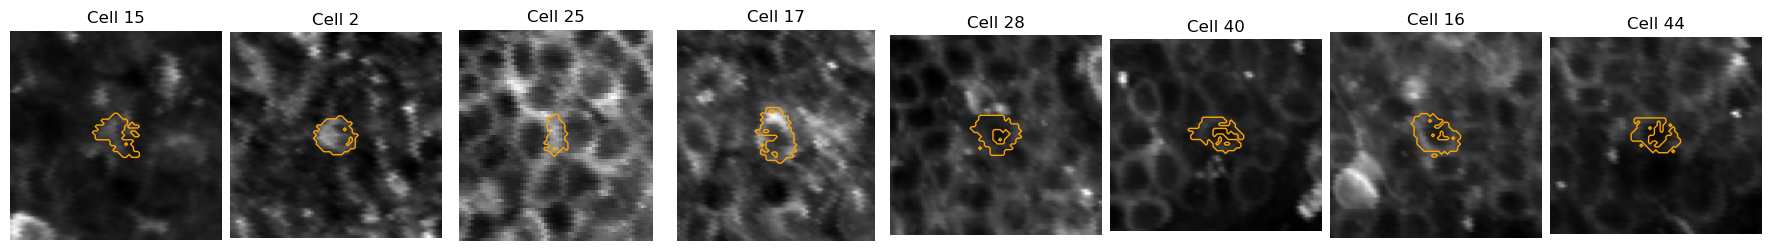

In [11]:
if single_experiment_ready:
    selected_cells = example_cell_ids[: min(8, example_cell_ids.size)]
    F = np.asarray(ctx.suite2p_ctx["F"], dtype=np.float32)

    fig, ax = plt.subplots(figsize=(9.5, max(5.5, 0.75 * len(selected_cells))), constrained_layout=True)
    offset = 0.0
    for cell_id in selected_cells:
        if cell_id >= F.shape[0]:
            continue
        y = robust_dff(F[cell_id])
        ax.plot(np.arange(y.size) / ctx.fps, y + offset, color=neuron_color, linewidth=0.9)
        peaks = exp_peaks.loc[exp_peaks["cell_id"].eq(cell_id), "all_peaks"].iloc[0]
        peaks = np.asarray(peaks, dtype=int)
        peaks = peaks[(peaks >= 0) & (peaks < y.size)]
        if peaks.size:
            ax.scatter(peaks / ctx.fps, y[peaks] + offset, s=12, color="red", edgecolors="none", alpha=0.9, zorder=4)
        n_sig = int(exp_peaks.loc[exp_peaks["cell_id"].eq(cell_id), "n_sig_clusters"].iloc[0])
        ax.text(-0.01 * y.size / ctx.fps, offset, f"{cell_id} ({n_sig})", ha="right", va="center", fontsize=8)
        offset += max(1.4, np.nanpercentile(y, 99) - np.nanpercentile(y, 1))
    ax.set_title("Automatically selected example cells: neuron dF/F with confirmed peaks")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("dF/F + offset")
    ax.spines[["top", "right"]].set_visible(False)
    fig.savefig(save_dir / "fig1/example_neuron_calcium_traces.svg", format="svg", bbox_inches="tight")

    plt.show()

    crop_pad_px = 28
    fig, axes = plt.subplots(1, len(selected_cells), figsize=(2.2 * len(selected_cells), 2.4), constrained_layout=True)
    axes = np.atleast_1d(axes)
    for ax, cell_id in zip(axes, selected_cells):
        outline = get_neuron_outline(int(cell_id), ctx.paths.suite2p_path, ctx.image_shape, spatial_bin=1)
        yx = np.argwhere(outline)
        if yx.size == 0:
            ax.text(0.5, 0.5, f"Cell {cell_id}\nno outline", transform=ax.transAxes, ha="center", va="center")
            ax.set_axis_off()
            continue
        y0, x0 = yx.min(axis=0)
        y1, x1 = yx.max(axis=0) + 1
        y0 = max(0, int(y0) - crop_pad_px); x0 = max(0, int(x0) - crop_pad_px)
        y1 = min(ctx.image_shape[0], int(y1) + crop_pad_px); x1 = min(ctx.image_shape[1], int(x1) + crop_pad_px)
        ax.imshow(ctx.neuron_mean_img[y0:y1, x0:x1], cmap="gray")
        ax.contour(outline[y0:y1, x0:x1].astype(float), levels=[0.5], colors=[neuron_color], linewidths=1.0)
        ax.set_title(f"Cell {cell_id}")
        ax.set_axis_off()

    fig.savefig(save_dir / "fig1/example_neuron_calcium_crops.svg", format="svg", bbox_inches="tight")
    plt.show()
else:
    print('Example-cell plots skipped: set SINGLE_EXPERIMENT to one available experiment.')


## Example Astrocyte Cluster Responses


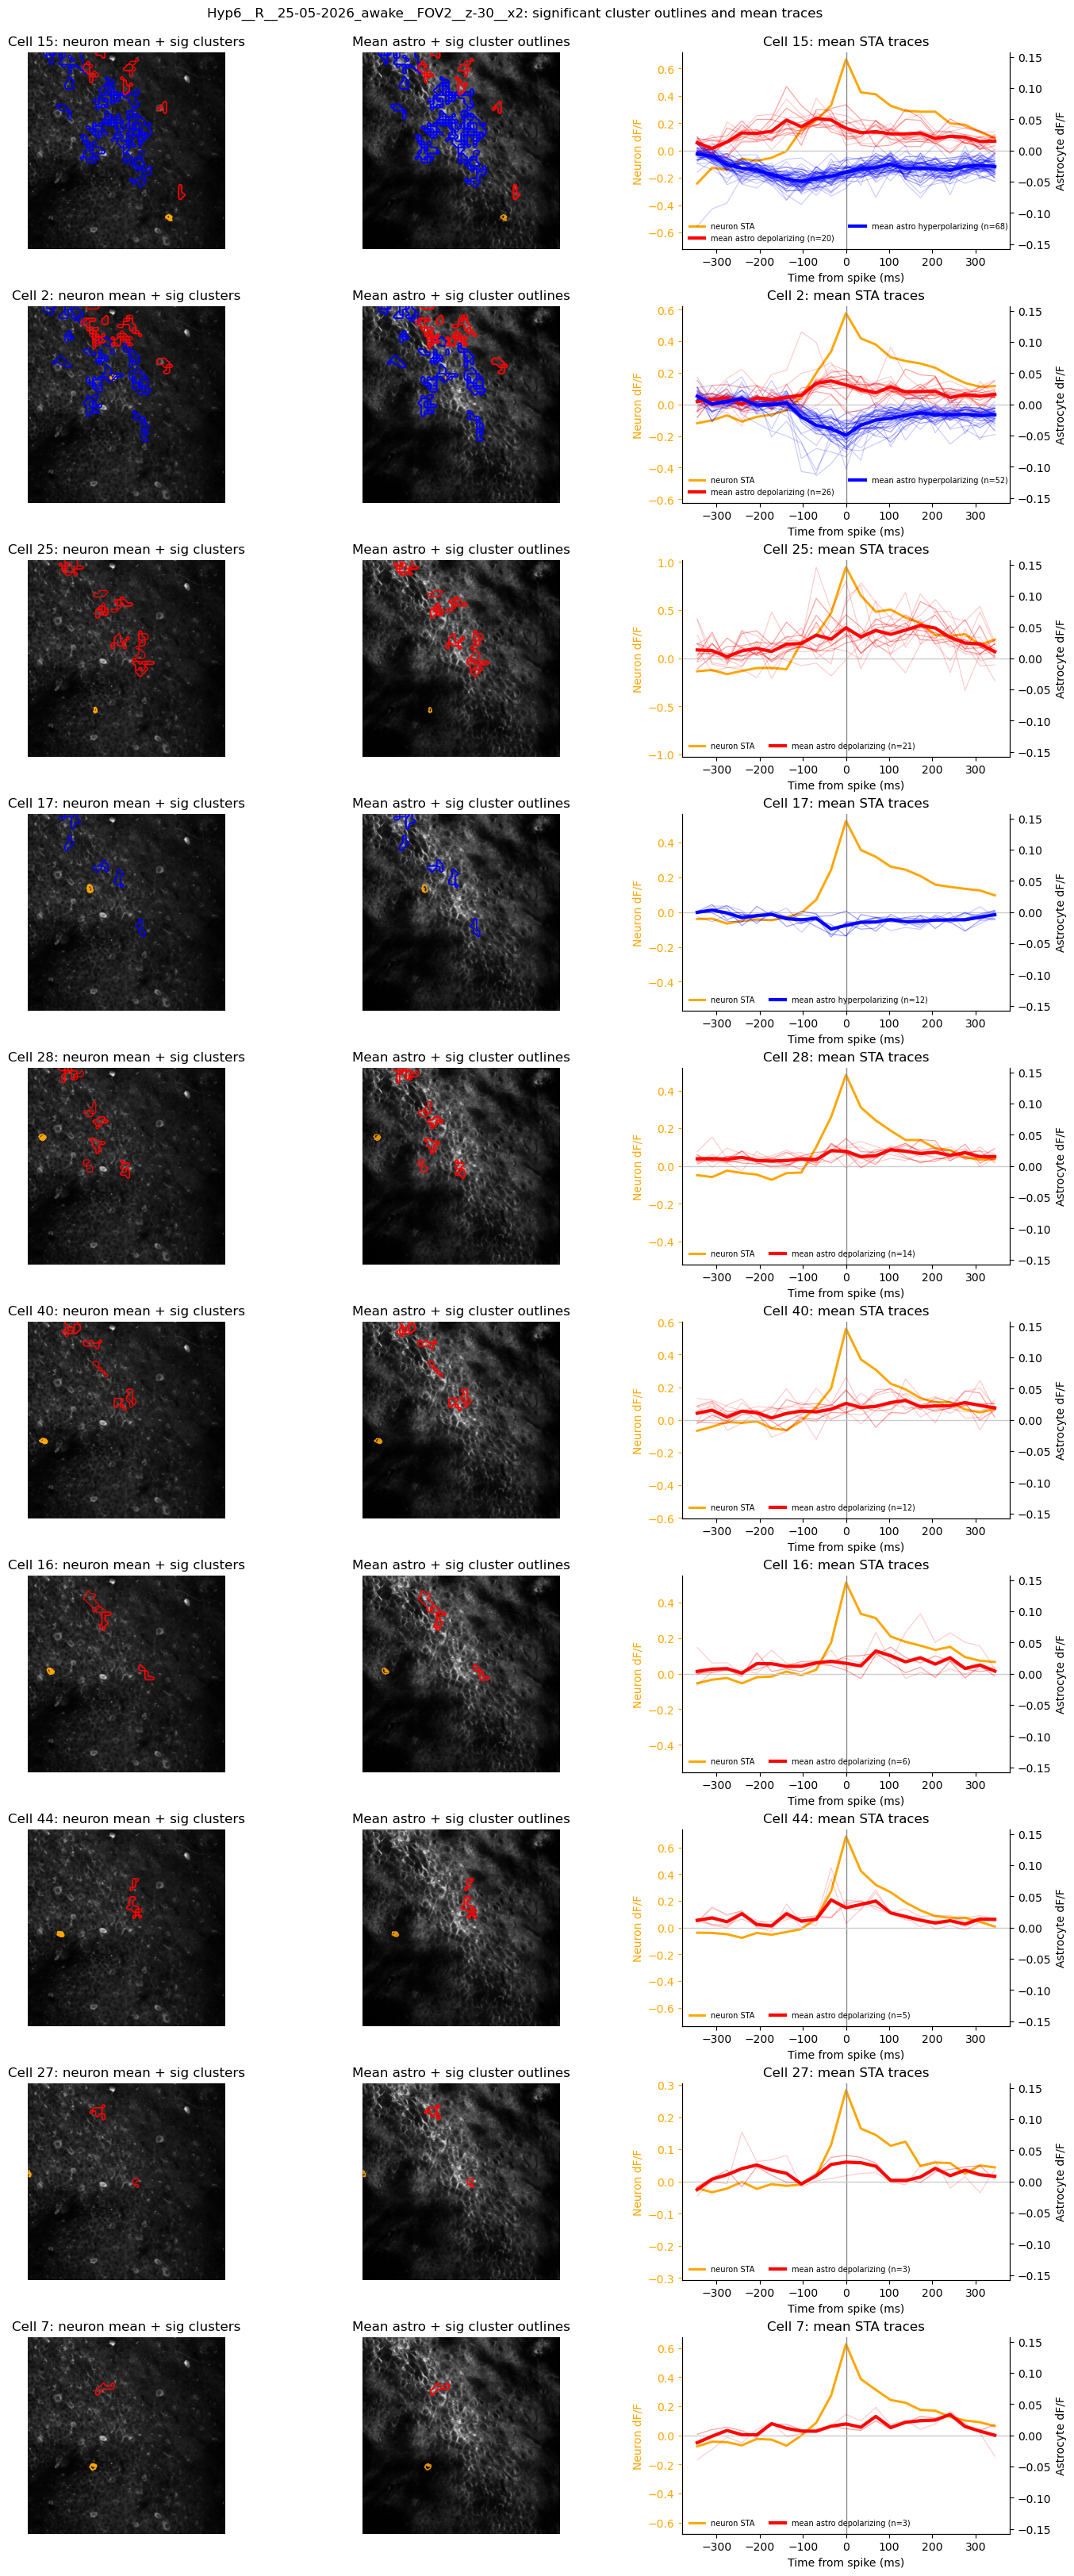

In [12]:
if single_experiment_ready:
    selected_cells = example_cell_ids[: min(10, example_cell_ids.size)]
    F = np.asarray(ctx.suite2p_ctx["F"], dtype=np.float32)

    def center_zero_ylim(ax, pad=0.08):
        ymin, ymax = ax.get_ylim()
        finite = [abs(v) for v in (ymin, ymax) if np.isfinite(v)]
        radius = max(finite) if finite else 1.0
        if radius == 0:
            radius = 1.0
        radius *= 1 + float(pad)
        ax.set_ylim(-radius, radius)

    astro_values_for_ylim = []
    neuron_sta_by_cell = {}
    for cell_id in selected_cells:
        rows = exp_sig_clusters[exp_sig_clusters["cell_id"].eq(int(cell_id))].copy()
        if not rows.empty:
            t_rel = np.asarray(rows.iloc[0]["t_rel"], dtype=int)
            pre_frames = int(abs(np.nanmin(t_rel)))
            post_frames = int(np.nanmax(t_rel))
            result_type = str(rows.iloc[0]["result_type"])
            peaks = np.asarray(exp_peaks.loc[exp_peaks["cell_id"].eq(int(cell_id)), "all_peaks"].iloc[0], dtype=np.int32)
            trace_dff = robust_dff(F[int(cell_id)])
            neuron_sta = compute_raw_sta_from_peaks(trace_dff, peaks, pre_frames, post_frames)
            neuron_sta = baseline_center_sta(neuron_sta, baseline_frames=min(10, pre_frames))
            neuron_sta_by_cell[int(cell_id)] = neuron_sta
        for cluster_row in rows.itertuples():
            y = np.asarray(cluster_row.mean_trace, dtype=float)
            if y.size:
                astro_values_for_ylim.append(y[np.isfinite(y)])
    if astro_values_for_ylim:
        astro_radius = max(float(np.nanmax(np.abs(np.concatenate(astro_values_for_ylim)))), 1e-6) * 1.08
    else:
        astro_radius = 1.0
    fig = plt.figure(figsize=(14, max(4.5, 3.2 * len(selected_cells))), constrained_layout=True)
    gs = fig.add_gridspec(len(selected_cells), 3, width_ratios=[1.0, 1.0, 1.0])

    for row_idx, cell_id in enumerate(selected_cells):
        rows = exp_sig_clusters[exp_sig_clusters["cell_id"].eq(int(cell_id))].copy()
        roi_mask = get_neuron_outline(int(cell_id), ctx.paths.suite2p_path, ctx.image_shape, spatial_bin=1).astype(bool)
        display_cluster_masks = []
        for _, cluster_row in rows.sort_values(["result_type", "sign", "cluster_id"]).iterrows():
            mask = full_fov_mask_from_row(cluster_row, ctx.image_shape)
            if mask is not None and mask.any():
                display_cluster_masks.append((cluster_row, mask))
        ax_neuron = fig.add_subplot(gs[row_idx, 0])
        ax_astro = fig.add_subplot(gs[row_idx, 1])
        ax_trace = fig.add_subplot(gs[row_idx, 2])

        ax_neuron.imshow(ctx.neuron_mean_img, cmap="gray")
        if roi_mask.any():
            ax_neuron.contour(roi_mask.astype(float), levels=[0.5], colors=[neuron_color], linewidths=1.4)
        for cluster_row, mask in display_cluster_masks:
            sign_key = str(cluster_row["sign"]).lower()
            color = polarity_color.get(sign_key, "0.4")
            if mask.any():
                ax_neuron.contour(mask, levels=[0.5], colors=[color], linewidths=1.0, alpha=0.9)
        ax_neuron.set_title(f"Cell {cell_id}: neuron mean + sig clusters")
        ax_neuron.set_axis_off()

        ax_astro.imshow(ctx.astro_mean_img, cmap="gray")
        if roi_mask.any():
            ax_astro.contour(roi_mask.astype(float), levels=[0.5], colors=[neuron_color], linewidths=1.0, alpha=0.9)
        for cluster_row, mask in display_cluster_masks:
            sign_key = str(cluster_row["sign"]).lower()
            color = polarity_color.get(sign_key, "0.4")
            if mask.any():
                ax_astro.contour(mask, levels=[0.5], colors=[color], linewidths=1.25, alpha=0.95)
        ax_astro.set_title("Mean astro + sig cluster outlines")
        ax_astro.set_axis_off()

        if rows.empty:
            ax_trace.text(0.5, 0.5, f"Cell {cell_id}: no significant clusters", transform=ax_trace.transAxes, ha="center", va="center")
            continue
        t_rel = np.asarray(rows.iloc[0]["t_rel"], dtype=int)
        x_ms = t_rel.astype(np.float32) * (1000.0 / float(ctx.fps))
        pre_frames = int(abs(np.nanmin(t_rel)))
        post_frames = int(np.nanmax(t_rel))
        neuron_sta = neuron_sta_by_cell[int(cell_id)]
        finite_neuron_sta = neuron_sta[np.isfinite(neuron_sta)]
        if finite_neuron_sta.size:
            neuron_local_radius = max(float(np.nanmax(np.abs(finite_neuron_sta))) * 1.08, 0.3)
        else:
            neuron_local_radius = 0.3
        ax_astro_trace = ax_trace.twinx()
        neuron_line = ax_trace.plot(x_ms, neuron_sta, color=neuron_color, linewidth=2.1, label="neuron STA")
        traces_by_sign = {"positive": [], "negative": []}
        for cluster_row in rows.sort_values(["result_type", "sign", "cluster_id"]).itertuples():
            y = np.asarray(cluster_row.mean_trace, dtype=float)
            if y.size != t_rel.size:
                continue
            sign_key = str(cluster_row.sign).lower()
            color = polarity_color.get(sign_key, "0.4")
            ax_astro_trace.plot(x_ms, y, color=color, linewidth=0.8, alpha=0.22)
            traces_by_sign.setdefault(sign_key, []).append(y)
        for sign_key in ["positive", "negative"]:
            traces = traces_by_sign.get(sign_key, [])
            if not traces:
                continue
            arr = np.vstack(traces)
            y_mean = np.nanmean(arr, axis=0)
            label = f"mean astro {polarity_label.get(sign_key, sign_key)} (n={arr.shape[0]})"
            ax_astro_trace.plot(x_ms, y_mean, color=polarity_color.get(sign_key, "0.4"), linewidth=3.0, alpha=0.98, label=label)
        ax_trace.set_ylim(-neuron_local_radius, neuron_local_radius)
        ax_astro_trace.set_ylim(-astro_radius, astro_radius)
        ax_trace.axvline(0, color="0.55", linewidth=1)
        ax_trace.axhline(0, color="0.8", linewidth=1)
        ax_trace.set_title(f"Cell {cell_id}: mean STA traces")
        ax_trace.set_xlabel("Time from spike (ms)")
        ax_trace.set_ylabel("Neuron dF/F", color=neuron_color)
        ax_astro_trace.set_ylabel("Astrocyte dF/F")
        ax_trace.tick_params(axis="y", colors=neuron_color)
        handles_left, labels_left = ax_trace.get_legend_handles_labels()
        handles_right, labels_right = ax_astro_trace.get_legend_handles_labels()
        dedup = dict(zip(labels_left + labels_right, handles_left + handles_right))
        ax_trace.legend(dedup.values(), dedup.keys(), frameon=False, fontsize=7, ncol=2, loc="best")
        ax_trace.spines[["top"]].set_visible(False)
        ax_astro_trace.spines[["top"]].set_visible(False)

    fig.suptitle(f"{ctx.canonical_id}: significant cluster outlines and mean traces", y=1.01)
    fig.savefig(save_dir / f"fig2/neuron_{cell_id}_sta_results.svg", format="svg", bbox_inches="tight")
    plt.show()
else:
    print('Example cluster-response plots skipped: set SINGLE_EXPERIMENT to one available experiment.')


# dF/F raw traces of master clusters

In [13]:
def _master_mask_for_sign(rows, sign_key, image_shape):
    master = np.zeros(tuple(image_shape), dtype=bool)
    for _, row in rows[rows["sign"].astype(str).str.lower().eq(sign_key)].iterrows():
        mask = full_fov_mask_from_row(row, image_shape)
        if mask is not None and mask.any():
            master |= np.asarray(mask, dtype=bool)
    return master

def _mask_trace_dff(movie, mask):
    if mask is None or not np.asarray(mask, dtype=bool).any():
        return None
    trace = np.asarray(movie[:, np.asarray(mask, dtype=bool)].mean(axis=1), dtype=float)
    return robust_dff(trace)

In [14]:
astro_movie = read_astro_movie(str(ctx.paths.astro_movie_path), as_memmap=True)
image_shape = tuple(int(v) for v in astro_movie.shape[1:])

Loading data...
Movie shape: (8400, 512, 512), dtype: float32


In [19]:
# Configurable raw master-cluster trace example.
RAW_TRACE_EXAMPLE_CELL_ID = 15

simple_peak_color = "tab:pink"
complex_peak_color = "tab:green"
raw_master_trace_ready = False

if single_experiment_ready:
    neuron_id = int(RAW_TRACE_EXAMPLE_CELL_ID)
    cell_rows = exp_cells[exp_cells["pipeline_neuron_id"].astype(int).eq(neuron_id)].copy()
    peak_rows = exp_peaks[exp_peaks["cell_id"].astype(int).eq(neuron_id)].copy()
    sig_rows = exp_sig_clusters[exp_sig_clusters["cell_id"].astype(int).eq(neuron_id)].copy()

    if cell_rows.empty:
        raise ValueError(f"Neuron {neuron_id} is not a confirmed DB neuron for {ctx.canonical_id}.")
    if peak_rows.empty:
        raise ValueError(f"Neuron {neuron_id} has no confirmed DB peak row for {ctx.canonical_id}.")

    F = np.asarray(ctx.suite2p_ctx["F"], dtype=np.float32)
    if neuron_id >= F.shape[0]:
        raise ValueError(f"Neuron {neuron_id} is outside Suite2p F with {F.shape[0]} rows.")
    neuron_dff = robust_dff(F[neuron_id])

    peaks_row = peak_rows.iloc[0]
    simple_peaks = np.asarray(peaks_row["simple_peaks"], dtype=np.int32)
    complex_peaks = np.asarray(peaks_row["complex_peaks"], dtype=np.int32)

    pos_master_cluster = _master_mask_for_sign(sig_rows, "positive", image_shape)
    neg_master_cluster = _master_mask_for_sign(sig_rows, "negative", image_shape)
    pos_master_trace_dff = _mask_trace_dff(astro_movie, pos_master_cluster)
    neg_master_trace_dff = _mask_trace_dff(astro_movie, neg_master_cluster)

    trace_candidates = [neuron_dff]
    if pos_master_trace_dff is not None:
        trace_candidates.append(pos_master_trace_dff)
    if neg_master_trace_dff is not None:
        trace_candidates.append(neg_master_trace_dff)
    trace_len = min(int(np.asarray(t).size) for t in trace_candidates)
    x_s = np.arange(trace_len, dtype=np.float32) / float(ctx.fps)
    neuron_dff = neuron_dff[:trace_len]
    if pos_master_trace_dff is not None:
        pos_master_trace_dff = pos_master_trace_dff[:trace_len]
    if neg_master_trace_dff is not None:
        neg_master_trace_dff = neg_master_trace_dff[:trace_len]

    raw_master_trace_ready = True
    print(f"Loaded raw master-cluster traces for {ctx.canonical_id}, neuron {neuron_id}.")
else:
    print("Raw master-cluster trace setup skipped: set SINGLE_EXPERIMENT to one available experiment.")


Loaded raw master-cluster traces for Hyp6__R__25-05-2026_awake__FOV2__z-30__x2, neuron 15.


In [21]:
%matplotlib widget

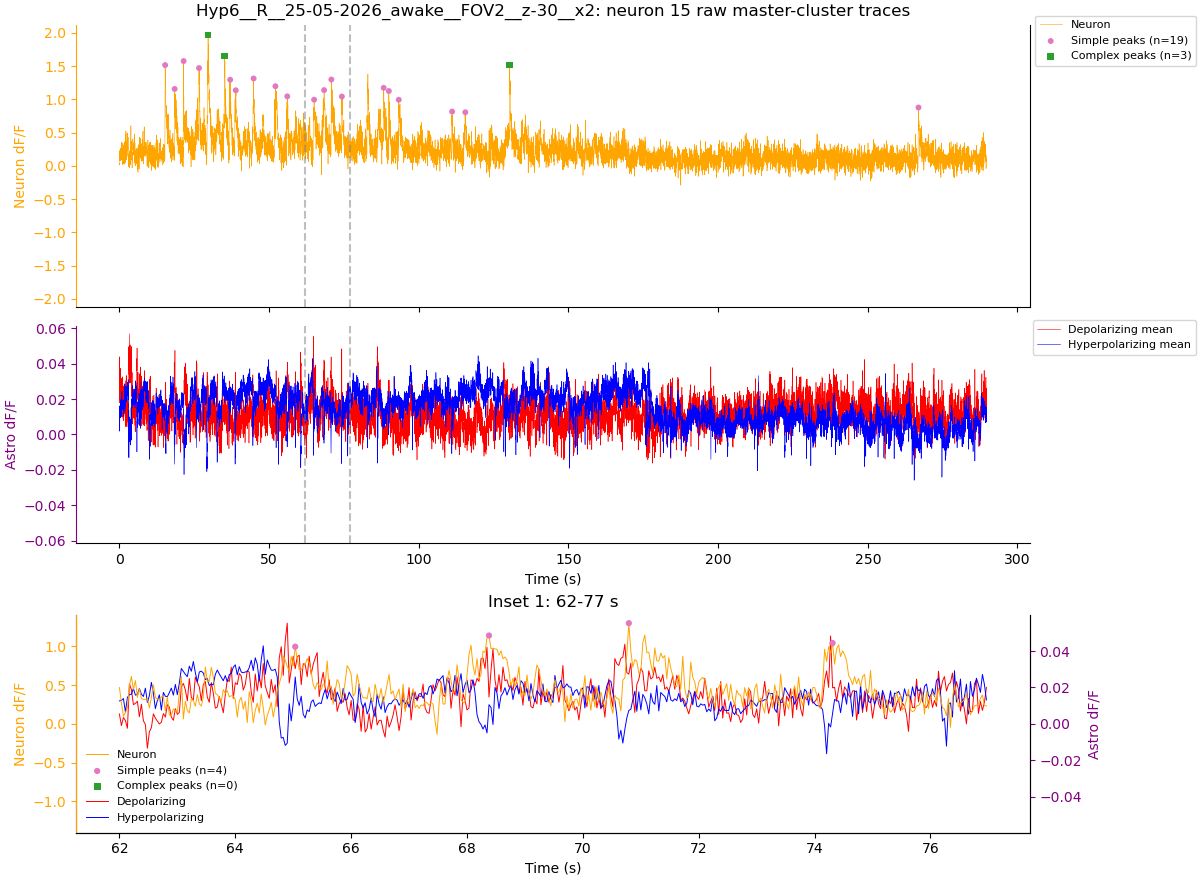

In [23]:
# Plot raw master-cluster traces. Rerun this cell when changing insets.
RAW_TRACE_INSETS_SECONDS = [(62, 77)]

if not raw_master_trace_ready:
    print("Raw master-cluster traces skipped: run the preceding setup/movie-loading cell first.")
else:
    def _plot_combined_window(ax_n, start, stop, title=None):
        start = max(0, int(start))
        stop = min(int(stop), trace_len)
        if stop <= start:
            ax_n.text(0.5, 0.5, "Empty window", transform=ax_n.transAxes, ha="center", va="center")
            ax_n.set_axis_off()
            return None
        ax_a = ax_n.twinx()
        ax_n.set_zorder(ax_a.get_zorder() + 1)
        ax_n.patch.set_visible(False)
        x_win = x_s[start:stop]
        neuron_win = neuron_dff[start:stop]
        ax_n.plot(x_win, neuron_win, color=neuron_color, lw=0.7, label="Neuron")
        astro_for_ylim = []
        if pos_master_trace_dff is not None:
            pos_win = pos_master_trace_dff[start:stop]
            astro_for_ylim.append(pos_win)
            ax_a.plot(x_win, pos_win, color=de_color, lw=0.7, label="Depolarizing")
        if neg_master_trace_dff is not None:
            neg_win = neg_master_trace_dff[start:stop]
            astro_for_ylim.append(neg_win)
            ax_a.plot(x_win, neg_win, color=hyper_color, lw=0.7, label="Hyperpolarizing")
        simple_in = simple_peaks[(simple_peaks >= start) & (simple_peaks < stop)]
        complex_in = complex_peaks[(complex_peaks >= start) & (complex_peaks < stop)]
        ax_n.scatter(x_s[simple_in], neuron_dff[simple_in], s=20, marker="o", color=simple_peak_color, edgecolors="none", zorder=6, label=f"Simple peaks (n={simple_in.size})")
        ax_n.scatter(x_s[complex_in], neuron_dff[complex_in], s=24, marker="s", color=complex_peak_color, edgecolors="none", zorder=6, label=f"Complex peaks (n={complex_in.size})")
        ax_n.set_ylim(*symmetric_ylim(neuron_win))
        if astro_for_ylim:
            ax_a.set_ylim(*symmetric_ylim(np.concatenate(astro_for_ylim)))
        ax_n.set_xlabel("Time (s)")
        ax_n.set_ylabel("Neuron dF/F", color=neuron_color)
        ax_a.set_ylabel("Astro dF/F", color=astro_color)
        ax_n.tick_params(axis="y", colors=neuron_color)
        ax_a.tick_params(axis="y", colors=astro_color)
        ax_n.spines["left"].set_color(neuron_color)
        ax_a.spines["right"].set_color(astro_color)
        ax_n.spines[["top"]].set_visible(False)
        ax_a.spines[["top"]].set_visible(False)
        handles_n, labels_n = ax_n.get_legend_handles_labels()
        handles_a, labels_a = ax_a.get_legend_handles_labels()
        ax_n.legend(handles_n + handles_a, labels_n + labels_a, frameon=False, fontsize=8, loc="best")
        if title is not None:
            ax_n.set_title(title)
        return ax_a

    n_insets = len(RAW_TRACE_INSETS_SECONDS)
    height_ratios = [1.3, 1.0] + [1.0] * n_insets
    fig, axes = plt.subplots(2 + n_insets, 1, figsize=(12, 6.2 + 2.6 * n_insets), sharex=False, height_ratios=height_ratios, constrained_layout=True)
    axes = np.atleast_1d(axes)
    ax_n0 = axes[0]
    ax_a0 = axes[1]
    ax_a0.sharex(ax_n0)

    ax_n0.plot(x_s, neuron_dff, color=neuron_color, lw=0.4, label="Neuron")
    simple_in = simple_peaks[(simple_peaks >= 0) & (simple_peaks < trace_len)]
    complex_in = complex_peaks[(complex_peaks >= 0) & (complex_peaks < trace_len)]
    ax_n0.scatter(x_s[simple_in], neuron_dff[simple_in], s=18, marker="o", color=simple_peak_color, edgecolors="none", zorder=6, label=f"Simple peaks (n={simple_in.size})")
    ax_n0.scatter(x_s[complex_in], neuron_dff[complex_in], s=22, marker="s", color=complex_peak_color, edgecolors="none", zorder=6, label=f"Complex peaks (n={complex_in.size})")
    astro_full_traces = []
    if pos_master_trace_dff is not None:
        astro_full_traces.append(pos_master_trace_dff)
        ax_a0.plot(x_s, pos_master_trace_dff, color=de_color, lw=0.4, label=f"Depolarizing mean")
    if neg_master_trace_dff is not None:
        astro_full_traces.append(neg_master_trace_dff)
        ax_a0.plot(x_s, neg_master_trace_dff, color=hyper_color, lw=0.4, label=f"Hyperpolarizing mean")
    ax_n0.set_ylim(*symmetric_ylim(neuron_dff))
    if astro_full_traces:
        ax_a0.set_ylim(*symmetric_ylim(np.concatenate(astro_full_traces)))
    ax_n0.set_ylabel("Neuron dF/F", color=neuron_color)
    ax_a0.set_ylabel("Astro dF/F", color=astro_color)
    ax_n0.tick_params(axis="x", labelbottom=False)
    ax_n0.tick_params(axis="y", colors=neuron_color)
    ax_a0.tick_params(axis="y", colors=astro_color)
    ax_n0.spines["left"].set_color(neuron_color)
    ax_a0.spines["left"].set_color(astro_color)
    ax_n0.spines[["top"]].set_visible(False)
    ax_a0.spines[["top", "right"]].set_visible(False)
    ax_a0.set_xlabel("Time (s)")
    ax_n0.set_title(f"{ctx.canonical_id}: neuron {neuron_id} raw master-cluster traces")

    for idx, seconds in enumerate(RAW_TRACE_INSETS_SECONDS, start=1):
        start_s, stop_s = [float(v) for v in seconds]
        start = int(round(start_s * float(ctx.fps)))
        stop = int(round(stop_s * float(ctx.fps)))
        for ax in (ax_n0, ax_a0):
            ax.axvline(start_s, linestyle="--", alpha=0.5, color="gray")
            ax.axvline(stop_s, linestyle="--", alpha=0.5, color="gray")
        _plot_combined_window(axes[idx + 1], start, stop, title=f"Inset {idx}: {start_s:g}-{stop_s:g} s")

    handles_n, labels_n = ax_n0.get_legend_handles_labels()
    handles_a, labels_a = ax_a0.get_legend_handles_labels()
    ax_n0.legend(handles_n, labels_n, loc="upper right", bbox_to_anchor=(1.18, 1.05), fontsize=8)
    ax_a0.legend(handles_a, labels_a, loc="upper right", bbox_to_anchor=(1.18, 1.05), fontsize=8)
    (save_dir / "fig2").mkdir(parents=True, exist_ok=True)
    fig.savefig(save_dir / f"fig2/raw_trace_neuron_{neuron_id}.svg", format="svg", bbox_inches="tight")
    plt.show()
